In [1]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap

In [3]:
def get_Voronoi_Cells_from_File(filename):
    file = open(filename)
    fileString = file.read().split("\n")
    file.close()
    Cells = {}
    for i in range(len(fileString) - 1):

        # Retrieve seed ID, seed location, and vertices from output file
        cell_string = fileString[i].split()
        seed_ID = int(cell_string[0])   # seed ID
        seed_loc = np.array([float(cell_string[1]), float(cell_string[2])])     # seed location
        vertices = []
        for j in range(3, len(cell_string)):
            vertex = [float(x) for x in cell_string[j][1:-1].split(",")]
            vertices.append(vertex)
        vertices = np.array(vertices)   # vertices that bound the region

        #  Sort vertices in traversal order
        angles = np.arctan2(vertices[:, 1] - seed_loc[1], vertices[:, 0] - seed_loc[0])
        vertices = vertices[np.argsort(angles)]
        vertices = np.vstack([vertices, vertices[0]])

        # Add to dictionary
        Cells[seed_ID] = {"seed": seed_loc, "vertices": np.column_stack(vertices)}
    return Cells

def get_IDs(Cells):
    return [cell_ID for cell_ID in Cells.keys()]

def get_Seeds(Cells):
    return np.array([cell['seed'] for cell in Cells.values()])

def get_Vertices(Cells):
    return [cell['vertices'] for cell in Cells.values()]

def get_Centroids_from_File(filename):
    file = open(filename)
    fileString = file.read().split()
    file.close()
    centroids = []

    points = [float(x) for x in fileString]
    for i in range(int(len(points)/3)):
        centroids.append(points[3*i+1:3*(i+1)])

    return np.column_stack(centroids)

In [69]:
def hideValue(cells, value):
    cells[cells == value] = 0
    return cells

In [82]:
colors = ["#e74c3c","#2ecc70", "#ffffff", "#00ae00", "#c00000", "#000000"]
# colors = ["#1abc9c", "#ffffff", "#000000"]
cmap = ListedColormap(colors)

In [5]:
from matplotlib import rc
rc('animation', html='jshtml')

In [92]:
file = open("output/DLA/dla_evolution.txt")
fileString = file.read().split("\n")
file.close()
num_seeds, min, max = [int(x) for x in fileString[0].split()]
iterations = len(fileString) - 1
CA_state_data = np.zeros((iterations, num_seeds))
for i in range(iterations):
  CA_state_data[i, :] = np.array([int(x) for x in fileString[i+1].split()])

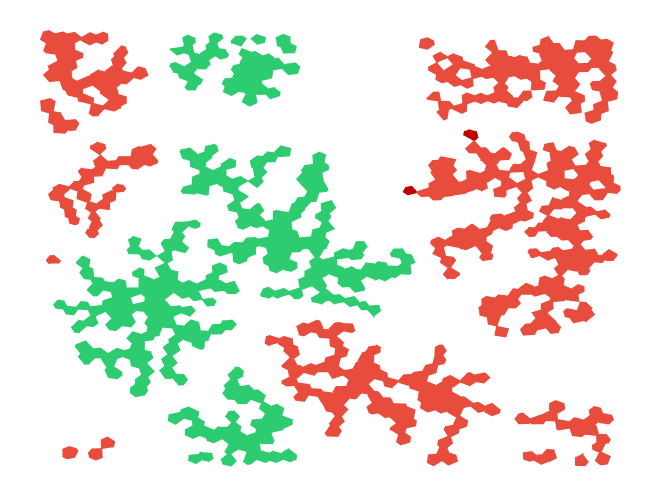

In [94]:
fig, ax = plt.subplots()
ax.set_axis_off()
plt.subplots_adjust(
    left=0,    # Left margin
    right=1,   # Right margin
    bottom=0,  # Bottom margin
    top=1,     # Top margin
)

Cells = get_Voronoi_Cells_from_File("output/DLA/dla_seeds.txt")
CIDs = get_IDs(Cells)
seeds = get_Seeds(Cells)
vertices = get_Vertices(Cells)

# CA_state_data = hideValue(CA_state_data, 1)
# CA_state_data = hideValue(CA_state_data, 2)
CA_state_data = hideValue(CA_state_data, 3)

ims = []
for i in range(iterations):
    frame_artists = []
    for j in range(len(CIDs)):
        seed_ID, seed_loc, verts = CIDs[j], seeds[j], vertices[j]
        color_index = int(CA_state_data[i, seed_ID]) - min

        # artist1, = ax.plot(verts[0], verts[1], color="black")
        # frame_artists.append(artist1)
        artist2, = ax.fill(verts[0], verts[1], color=colors[color_index], alpha=1)
        frame_artists.append(artist2)

    ims.append(frame_artists)
    
ani = animation.ArtistAnimation(fig, ims, blit=True)
ani.save("output/static_Voro_CA_animation.gif",  writer="ffmpeg", fps=5)